In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
!pip -q install pyreadr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 788.4/788.4 kB 19.4 MB/s eta 0:00:00


In [5]:
import pyreadr

result = pyreadr.read_r("/content/congress.RData")

print(result.keys())

odict_keys(['congress'])


In [6]:
congress = result["congress"]

print(congress.shape)
display(congress.head())

(220, 11)


,bioguide_id,first_name,last_name,full_name,gender,party,state,chamber,birth_year,twitter,wikipedia_id
rownames,,,,,,,,,,,
1,B001000,James,Moore,James Moore,M,Democrat,FL,Senate,1951.0,SenMoore70,James_Moore
2,B001001,Patricia,Johnson,Patricia Johnson,F,Democrat,IA,Senate,1977.0,SenJohnson72,Patricia_Johnson
3,B001002,Sarah,Lewis,Sarah Lewis,F,Republican,AL,Senate,1955.0,SenLewis44,Sarah_Lewis
4,B001003,Mark,Miller,Mark Miller,M,Democrat,CT,Senate,1967.0,SenMiller78,Mark_Miller
5,B001004,Brian,Wright,Brian Wright,M,Democrat,MO,Senate,1950.0,SenWright81,Brian_Wright


In [7]:
CURRENT_YEAR = 2026

congress["age"] = CURRENT_YEAR - congress["birth_year"]

display(congress[["full_name", "gender", "birth_year", "age"]].head())

,full_name,gender,birth_year,age
rownames,,,,
1,James Moore,M,1951.0,75.0
2,Patricia Johnson,F,1977.0,49.0
3,Sarah Lewis,F,1955.0,71.0
4,Mark Miller,M,1967.0,59.0
5,Brian Wright,M,1950.0,76.0


In [8]:
average_age = congress.groupby("gender")["age"].mean()

print(average_age)

gender
F    61.194690
M    61.934579
Name: age, dtype: float64


<Figure size 800x600 with 0 Axes>

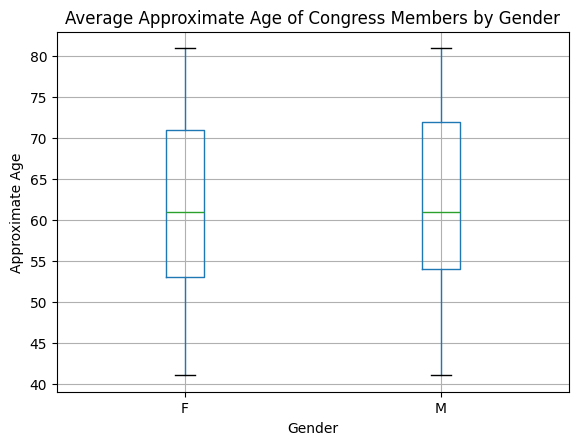

In [9]:
plt.figure(figsize=(8, 6))

congress.boxplot(
    column="age",
    by="gender"
)

plt.title("Average Approximate Age of Congress Members by Gender")
plt.suptitle("")
plt.xlabel("Gender")
plt.ylabel("Approximate Age")

plt.show()

In [10]:
print(congress.columns.tolist())

['bioguide_id', 'first_name', 'last_name', 'full_name', 'gender', 'party', 'state', 'chamber', 'birth_year', 'twitter', 'wikipedia_id', 'age']


In [11]:
display(
    congress[["full_name", "twitter", "wikipedia_id"]].head(10)
)

,full_name,twitter,wikipedia_id
rownames,,,
1,James Moore,SenMoore70,James_Moore
2,Patricia Johnson,SenJohnson72,Patricia_Johnson
3,Sarah Lewis,SenLewis44,Sarah_Lewis
4,Mark Miller,SenMiller78,Mark_Miller
5,Brian Wright,SenWright81,Brian_Wright
6,Michelle Gonzalez,SenGonzalez11,NaN
7,Steven Moore,SenMoore27,Steven_Moore
8,Jason Hernandez,SenHernandez35,NaN
9,Mark Brown,SenBrown9,Mark_Brown


In [12]:
congress["social_media_accounts"] = congress["twitter"].notna().astype(int)

print(congress["social_media_accounts"].value_counts())

display(
    congress[
        ["full_name", "age", "twitter", "social_media_accounts"]
    ].head(10)
)

social_media_accounts
1    196
0     24
Name: count, dtype: int64


,full_name,age,twitter,social_media_accounts
rownames,,,,
1,James Moore,75.0,SenMoore70,1
2,Patricia Johnson,49.0,SenJohnson72,1
3,Sarah Lewis,71.0,SenLewis44,1
4,Mark Miller,59.0,SenMiller78,1
5,Brian Wright,76.0,SenWright81,1
6,Michelle Gonzalez,67.0,SenGonzalez11,1
7,Steven Moore,71.0,SenMoore27,1
8,Jason Hernandez,71.0,SenHernandez35,1
9,Mark Brown,61.0,SenBrown9,1


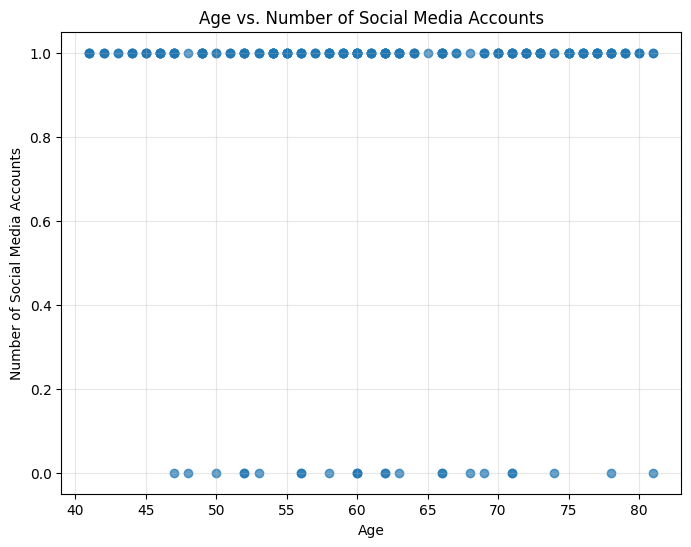

In [13]:
plt.figure(figsize=(8, 6))

plt.scatter(
    congress["age"],
    congress["social_media_accounts"],
    alpha=0.7
)

plt.xlabel("Age")
plt.ylabel("Number of Social Media Accounts")
plt.title("Age vs. Number of Social Media Accounts")
plt.grid(True, alpha=0.3)

plt.show()

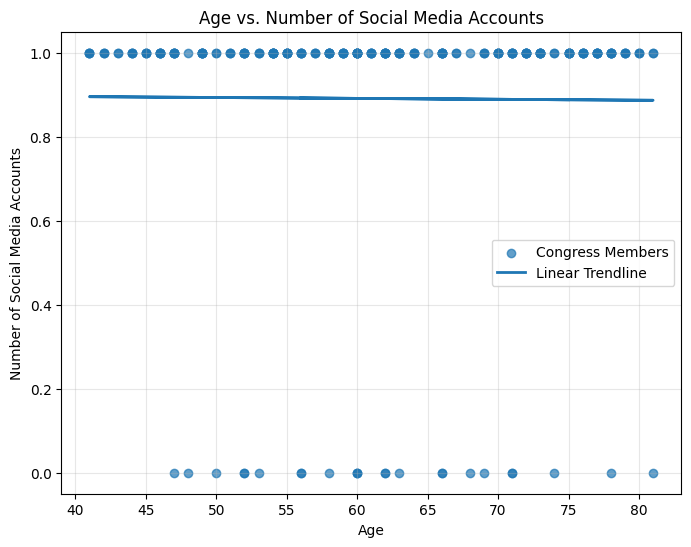

Slope: -0.0002142795039942986
Intercept: 0.9040989683776854


In [14]:
import numpy as np

x = congress["age"].values
y = congress["social_media_accounts"].values

slope, intercept = np.polyfit(x, y, 1)

trendline = slope * x + intercept

plt.figure(figsize=(8, 6))

plt.scatter(
    congress["age"],
    congress["social_media_accounts"],
    alpha=0.7,
    label="Congress Members"
)

plt.plot(
    x,
    trendline,
    linewidth=2,
    label="Linear Trendline"
)

plt.xlabel("Age")
plt.ylabel("Number of Social Media Accounts")
plt.title("Age vs. Number of Social Media Accounts")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

print("Slope:", slope)
print("Intercept:", intercept)

In [15]:
!pip -q install statsmodels

In [16]:
import statsmodels.formula.api as smf

congress["type"] = congress["chamber"].map({
    "Senate": "Senator",
    "House": "Representative"
})

congress["party"] = congress["party"].astype("category")
congress["gender"] = congress["gender"].astype("category")

print(congress[["age", "social_media_accounts", "type", "party", "gender"]].head())

           age  social_media_accounts     type       party gender
rownames                                                         
1         75.0                      1  Senator    Democrat      M
2         49.0                      1  Senator    Democrat      F
3         71.0                      1  Senator  Republican      F
4         59.0                      1  Senator    Democrat      M
5         76.0                      1  Senator    Democrat      M


In [17]:
model = smf.ols(
    "social_media_accounts ~ C(type) + age + C(party) + C(gender)",
    data=congress
).fit()

print(model.summary())

                              OLS Regression Results                             
Dep. Variable:     social_media_accounts   R-squared:                       0.008
Model:                               OLS   Adj. R-squared:                 -0.016
Method:                    Least Squares   F-statistic:                    0.3290
Date:                   Thu, 10 Sep 2026   Prob (F-statistic):              0.895
Time:                           11:11:31   Log-Likelihood:                -54.905
No. Observations:                    220   AIC:                             121.8
Df Residuals:                        214   BIC:                             142.2
Df Model:                              5                                         
Covariance Type:               nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------

In [18]:
print("Age coefficient:", model.params["age"])

Age coefficient: -0.00015811309547935417


In [19]:
print("R-squared:", model.rsquared)
print("Adjusted R-squared:", model.rsquared_adj)
print("Age coefficient:", model.params["age"])
print("Age p-value:", model.pvalues["age"])

R-squared: 0.007627872983023809
Adjusted R-squared: -0.015558391666905536
Age coefficient: -0.00015811309547935417
Age p-value: 0.9349385550603213
